# Phase 19 — Multi-Seed Robustness Check

**Notebook:** `18_multiseed_robustness.ipynb`

## Why this notebook exists

Phase 16 (`15_fusion_model.ipynb`) found that a simple unweighted average of
`DualBranchGAT`'s and the TCI baseline's out-of-fold probabilities
(`Fusion_B_unweighted_avg`) significantly beats the TCI baseline alone
(DeLong p = 0.0329) — using **one** 5-fold split (`random_state=42`).

A p-value this close to 0.05 needs to be checked for robustness before it is
reported as a real finding. This notebook repeats the entire pipeline — GAT
5-fold CV, TCI-baseline 5-fold CV, fusion, DeLong test — across **4 total
random seeds** (42, the original, plus 3 new: 7, 123, 2024) and reports
honestly whether the significant result holds up, or was specific to one
lucky split.

**Files read (never modified):** `data/processed/subject_metadata.csv`,
`data/processed/graph_manifest.csv`, `data/processed/split_manifest.csv`
(see the note in Section 1b for why this last file is also needed),
`data/processed/normalization_stats.json` (reused exactly as-is, not
recomputed — same convention as every prior phase). No raw Excel file, no
raw dataset directory, and no existing checkpoint from Phases 10–17 is
touched — this notebook trains its own fresh checkpoints under
`checkpoints/robustness_seed{SEED}_fold{FOLD}_best.pt`.

**Runtime note:** this notebook trains 4 seeds × 5 folds = 20 fresh
`DualBranchGAT` models (plus 20 TCI baseline folds), so it takes
noticeably longer than any prior single-seed notebook — roughly 4× Phase
13's (`12_cross_validation.ipynb`) runtime.


## Section 1 — Setup

Import libraries, detect the device, define the 4 seeds and the primary
architecture config (identical to `PRIMARY_CONFIG` in every training phase
since Phase 10), and make sure the `results/` and `checkpoints/` output
folders exist.


In [1]:
print("=== SECTION 1: Setup ===")

import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import time
import json
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    f1_score,
    accuracy_score,
    roc_curve,
)
import scipy.stats
import matplotlib.pyplot as plt

from src.dataset import PlantarThermographyDataset
from src.model import DualBranchGAT
from src.train import build_model, train_model, evaluate
from src.mc_dropout import mc_dropout_predict

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

DATA_DIR = Path("data/processed")
CHECKPOINT_DIR = Path("checkpoints")
RESULTS_DIR = Path("results")
CHECKPOINT_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

SEEDS = [42, 7, 123, 2024]
PRIMARY_CONFIG = {
    "use_graph_branch": True,
    "use_image_branch": True,
    "graph_topology": "base",
    "image_key": "colormap_image",
    "image_in_channels": 3,
}
print(f"SEEDS to test: {SEEDS}  (42 reproduces Phase 13/14/16's original result; 7, 123, 2024 are new)")
print(f"PRIMARY_CONFIG: {PRIMARY_CONFIG}")

# Project color convention (Control = blue, DM = orange), reused for plots below.
DM_COLOR = "#ff7f0e"
CONTROL_COLOR = "#1f77b4"

# Running tally of any integrity issues found in this notebook, printed in
# the final summary cell (same convention as Phase 16).
issues_found = []

subject_metadata_df = pd.read_csv(DATA_DIR / "subject_metadata.csv")
print(f"subject_metadata_df shape: {subject_metadata_df.shape}")
assert subject_metadata_df.shape[0] == 167, "Expected 167 subjects in subject_metadata.csv"


=== SECTION 1: Setup ===
Using device: cuda
SEEDS to test: [42, 7, 123, 2024]  (42 reproduces Phase 13/14/16's original result; 7, 123, 2024 are new)
PRIMARY_CONFIG: {'use_graph_branch': True, 'use_image_branch': True, 'graph_topology': 'base', 'image_key': 'colormap_image', 'image_in_channels': 3}
subject_metadata_df shape: (167, 19)


### Section 1b — Building `combined_manifest_df`

**Note on files read:** the task spec for this notebook lists
`graph_manifest.csv` as the file to enumerate every subject+foot row from,
but `PlantarThermographyDataset` (Phase 7) also needs the image-branch
array/PNG paths that live in `split_manifest.csv`, not `graph_manifest.csv`
— since `PRIMARY_CONFIG` uses the `colormap_image` branch
(`use_image_branch=True`). This mirrors Phase 13's (`12_cross_validation.ipynb`)
precedent exactly: both files are read and merged into `combined_manifest_df`,
the same way Phase 7 originally built it, with its `split` column dropped
(Phase 5's old fixed split is not used here — this notebook builds its own
per-seed fold assignments instead).


In [2]:
print("=== SECTION 1b: Building combined_manifest_df ===")

split_manifest_df = pd.read_csv(DATA_DIR / "split_manifest.csv")
graph_manifest_df = pd.read_csv(DATA_DIR / "graph_manifest.csv")
print(f"split_manifest_df shape: {split_manifest_df.shape}")
print(f"graph_manifest_df shape: {graph_manifest_df.shape}")

combined_manifest_df = split_manifest_df.merge(
    graph_manifest_df, on=["subject_id", "foot_side"], suffixes=("", "_graph")
)

mismatch_total = 0
for col in ["group", "gender"]:
    mismatches = (combined_manifest_df[col] != combined_manifest_df[f"{col}_graph"]).sum()
    mismatch_total += mismatches
    print(f"  Column '{col}' mismatch count between split_manifest and graph_manifest: {mismatches}")
print("PASS" if mismatch_total == 0 else "FAIL", "-- combined_manifest_df merge consistency check")
if mismatch_total != 0:
    issues_found.append(f"combined_manifest_df group/gender mismatch count: {mismatch_total}")
assert mismatch_total == 0

combined_manifest_df = combined_manifest_df.drop(
    columns=[c for c in combined_manifest_df.columns if c.endswith("_graph")]
)
# 'split' is Phase 5's old fixed 70/15/15 assignment -- ignored here, this
# notebook builds its own per-seed fold assignments. Dropped so it can't be
# accidentally relied on downstream; build_fold_dataset() below re-labels it
# per fold role, same convention as Phase 13.
combined_manifest_df = combined_manifest_df.drop(columns=["split"])

print(f"combined_manifest_df shape: {combined_manifest_df.shape} (expected (334, 14))")
assert len(combined_manifest_df) == 334

with open(DATA_DIR / "normalization_stats.json") as f:
    normalization_stats = json.load(f)
print("normalization_stats.json loaded (reused exactly as-is from Phase 7, not recomputed here).")


=== SECTION 1b: Building combined_manifest_df ===
split_manifest_df shape: (334, 15)
graph_manifest_df shape: (334, 9)
  Column 'group' mismatch count between split_manifest and graph_manifest: 0
  Column 'gender' mismatch count between split_manifest and graph_manifest: 0
PASS -- combined_manifest_df merge consistency check
combined_manifest_df shape: (334, 18) (expected (334, 14))
normalization_stats.json loaded (reused exactly as-is from Phase 7, not recomputed here).


## Section 2 — Reimplement the DeLong Test

Same self-contained numpy reimplementation used in Phases 14 and 16 (Sun &
Xu 2014 fast/midrank formulation) — reimplemented directly here, no
cross-notebook import. A quick synthetic sanity check confirms the AUC
computation matches `sklearn.metrics.roc_auc_score` before it is trusted on
any real seed's results below.


In [3]:
print("=== SECTION 2: Reimplement the DeLong Test ===")


def _compute_midrank(x):
    """Midranks of x, handling ties (Sun & Xu 2014)."""
    J = np.argsort(x)
    Z = x[J]
    N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    T2 = np.empty(N, dtype=float)
    T2[J] = T
    return T2


def _fast_delong(preds_sorted_transposed, label_1_count):
    """
    preds_sorted_transposed: (n_classifiers, n_examples), with the positive
    (label==1) examples first, negative examples after.
    Returns (aucs, covariance matrix) per Sun & Xu's fast DeLong algorithm.
    """
    m = label_1_count
    n = preds_sorted_transposed.shape[1] - m
    k = preds_sorted_transposed.shape[0]

    positive_examples = preds_sorted_transposed[:, :m]
    negative_examples = preds_sorted_transposed[:, m:]

    tx = np.empty([k, m], dtype=float)
    ty = np.empty([k, n], dtype=float)
    tz = np.empty([k, m + n], dtype=float)
    for r in range(k):
        tx[r, :] = _compute_midrank(positive_examples[r, :])
        ty[r, :] = _compute_midrank(negative_examples[r, :])
        tz[r, :] = _compute_midrank(preds_sorted_transposed[r, :])

    aucs = tz[:, :m].sum(axis=1) / (m * n) - (m + 1.0) / (2.0 * n)
    v01 = (tz[:, :m] - tx[:, :]) / n
    v10 = 1.0 - (tz[:, m:] - ty[:, :]) / m
    sx = np.cov(v01)
    sy = np.cov(v10)
    delongcov = sx / m + sy / n
    return aucs, delongcov


def delong_roc_test(true_label, prob_a, prob_b):
    """
    Paired DeLong test comparing two sets of predicted probabilities against
    the same true binary labels (same subjects, correctly paired).

    Returns a dict: auc_a, auc_b, auc_diff (a - b), z, p_value.
    """
    true_label = np.asarray(true_label)
    prob_a = np.asarray(prob_a, dtype=float)
    prob_b = np.asarray(prob_b, dtype=float)

    order = np.argsort(-true_label)  # positives (label==1) first
    label_1_count = int(np.sum(true_label))

    preds_sorted_transposed = np.vstack([prob_a, prob_b])[:, order]
    aucs, delongcov = _fast_delong(preds_sorted_transposed, label_1_count)

    auc_a, auc_b = float(aucs[0]), float(aucs[1])
    auc_diff = auc_a - auc_b
    var = delongcov[0, 0] + delongcov[1, 1] - 2 * delongcov[0, 1]
    se = float(np.sqrt(var)) if var > 0 else 0.0
    z = auc_diff / se if se > 0 else 0.0
    p_value = 2 * (1 - scipy.stats.norm.cdf(abs(z))) if se > 0 else 1.0

    return {"auc_a": auc_a, "auc_b": auc_b, "auc_diff": auc_diff, "z": z, "p_value": p_value}


# Sanity check on synthetic data: delong_roc_test's own AUC computation
# should agree with sklearn's roc_auc_score before this is trusted on any
# real seed's results below.
_rng = np.random.RandomState(0)
_y_check = _rng.randint(0, 2, size=200)
_p1_check = _rng.rand(200)
_p2_check = _rng.rand(200)
_check = delong_roc_test(_y_check, _p1_check, _p2_check)
_sk_auc1 = roc_auc_score(_y_check, _p1_check)
_sk_auc2 = roc_auc_score(_y_check, _p2_check)
_match = np.isclose(_check["auc_a"], _sk_auc1) and np.isclose(_check["auc_b"], _sk_auc2)
print(f"DeLong-computed AUC vs. sklearn roc_auc_score (synthetic data): {'PASS' if _match else 'FAIL'}")
if not _match:
    issues_found.append("delong_roc_test AUC computation did not match sklearn on synthetic sanity check")
assert _match


=== SECTION 2: Reimplement the DeLong Test ===
DeLong-computed AUC vs. sklearn roc_auc_score (synthetic data): PASS


## Section 3 — Per-Seed, Per-Fold Pipeline

For each of the 4 `SEEDS`, this section:

1. Builds 5 stratified folds on the 167 subjects
   (`StratifiedKFold(random_state=SEED)`), each fold's non-test subjects
   further split 90/10 (stratified, `random_state=SEED`) into train/val —
   same fold-construction method as Phase 13, just parameterized by seed
   instead of hardcoded to 42.
2. Trains a fresh `DualBranchGAT` per fold (`PRIMARY_CONFIG`, identical
   hyperparameters to every prior training phase: `max_epochs=150,
   patience=20, lr=1e-3, weight_decay=1e-4`), reloads the best checkpoint,
   computes that fold's own Youden's-J threshold from its own val
   predictions, and runs `mc_dropout_predict` (T=30) on that fold's test
   subjects — exactly as Phase 13 did.
3. Trains a TCI-only `LogisticRegression(class_weight='balanced')`
   baseline on `worse_foot_tci = max(RIGHT_TCI, LEFT_TCI)` through the same
   5 folds — exactly as Phase 14 did.
4. Pools both models' out-of-fold probabilities into one 167-subject array
   per seed, fuses them via the Phase 16 winner
   (`0.5 * gat_prob + 0.5 * baseline_prob`), and runs the Section 2 DeLong
   test comparing the fusion against each individual model.

The helper functions below (`build_fold_dataset`, `build_fold_dataloaders`,
`compute_fold_class_weights`, `collect_predictions`, `youden_j_threshold`,
`run_mc_dropout_over_loader`) are the same pattern established in Phase
13's `12_cross_validation.ipynb`, generalized to accept an arbitrary
`seed` rather than being hardcoded to 42. `collect_predictions()` runs its
own plain forward pass (rather than relying on `evaluate()`'s internal key
names for its raw labels/probabilities) for the same reason Phase 13 did —
it keeps this notebook self-contained without depending on `src/train.py`'s
exact internal return-dict keys.


In [4]:
print("=== SECTION 3: Helper Functions ===")


def build_fold_dataset(subject_ids, split_label, manifest_df, norm_stats):
    """Same lightweight per-fold Dataset builder as Phase 13: filters
    combined_manifest_df by an arbitrary subject_id list and re-labels the
    'split' column so PlantarThermographyDataset's returned metadata
    reflects this fold's role."""
    subset_df = manifest_df[manifest_df["subject_id"].isin(subject_ids)].copy()
    subset_df["split"] = split_label
    return PlantarThermographyDataset(subset_df, norm_stats)


def build_fold_dataloaders(fold, manifest_df, norm_stats, batch_size=16):
    train_ds = build_fold_dataset(fold["train_ids"], "train", manifest_df, norm_stats)
    val_ds = build_fold_dataset(fold["val_ids"], "val", manifest_df, norm_stats)
    test_ds = build_fold_dataset(fold["test_ids"], "test", manifest_df, norm_stats)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

    return {
        "train_dataset": train_ds, "val_dataset": val_ds, "test_dataset": test_ds,
        "train_loader": train_loader, "val_loader": val_loader, "test_loader": test_loader,
    }


def compute_fold_class_weights(train_ids, subject_metadata_df):
    train_meta = subject_metadata_df[subject_metadata_df["Subject"].isin(train_ids)]
    counts = train_meta["Group"].value_counts()
    n_train = len(train_meta)
    weight_control = n_train / (2 * counts.get("Control", 1))
    weight_dm = n_train / (2 * counts.get("DM", 1))
    return weight_control, weight_dm


def build_seed_folds(subject_ids_all, groups_all, seed):
    """5 stratified folds for a given seed; each fold's non-test subjects
    further split 90/10 (stratified) into train/val. Same method as Phase
    13, parameterized by seed instead of hardcoded to 42."""
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    folds = []
    for fold_idx, (trainval_idx, test_idx) in enumerate(skf.split(subject_ids_all, groups_all)):
        trainval_ids = subject_ids_all[trainval_idx]
        trainval_groups = groups_all[trainval_idx]
        test_ids = subject_ids_all[test_idx]
        train_ids, val_ids = train_test_split(
            trainval_ids, test_size=0.10, stratify=trainval_groups, random_state=seed,
        )
        folds.append({
            "fold_idx": fold_idx,
            "train_ids": list(train_ids),
            "val_ids": list(val_ids),
            "test_ids": list(test_ids),
        })
    return folds


def collect_predictions(model, loader, device, graph_topology, image_key):
    """Plain (non-MC-Dropout) forward pass, collecting labels and sigmoid
    probabilities -- used for threshold selection so this notebook doesn't
    depend on evaluate()'s exact internal key names for its raw
    (labels, probabilities) arrays."""
    model.eval()
    all_labels, all_probs = [], []
    with torch.no_grad():
        for batch in loader:
            batch_device = {
                k: (v.to(device) if torch.is_tensor(v) else v) for k, v in batch.items()
            }
            logits = model(batch_device, graph_topology=graph_topology, image_key=image_key)
            probs = torch.sigmoid(logits).cpu().numpy()
            labels = batch["label"].cpu().numpy()
            all_probs.append(probs)
            all_labels.append(labels)
    return np.concatenate(all_labels), np.concatenate(all_probs)


def youden_j_threshold(labels, probs):
    fpr, tpr, thresholds = roc_curve(labels, probs)
    j_scores = tpr - fpr
    best_idx = np.argmax(j_scores)
    return thresholds[best_idx]


def run_mc_dropout_over_loader(model, loader, dataset, T, graph_topology, image_key, device):
    """Runs mc_dropout_predict per batch and returns a per-foot DataFrame
    with subject_id/foot_side/group read from dataset.manifest_df (relying
    on shuffle=False for order), plus mc_mean_prob -- same pattern as
    Phase 13. Only mean_prob is needed here (this notebook only reports
    pooled AUC, not the full uncertainty decomposition)."""
    all_mean_prob, all_label = [], []
    for batch in loader:
        batch_device = {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in batch.items()}
        mc_out = mc_dropout_predict(model, batch_device, T=T, graph_topology=graph_topology, image_key=image_key)
        all_mean_prob.append(mc_out["mean_prob"].cpu().numpy())
        all_label.append(batch_device["label"].cpu().numpy())

    mean_prob = np.concatenate(all_mean_prob)
    manifest_df = dataset.manifest_df.reset_index(drop=True)
    assert len(mean_prob) == len(manifest_df), "MC-Dropout output length must match dataset length (shuffle=False)"

    out_df = manifest_df[["subject_id", "foot_side", "group"]].copy()
    out_df["true_label"] = np.concatenate(all_label)
    out_df["mc_mean_prob"] = mean_prob
    return out_df


print("Helper functions defined: build_fold_dataset, build_fold_dataloaders, "
      "compute_fold_class_weights, build_seed_folds, collect_predictions, "
      "youden_j_threshold, run_mc_dropout_over_loader")


=== SECTION 3: Helper Functions ===
Helper functions defined: build_fold_dataset, build_fold_dataloaders, compute_fold_class_weights, build_seed_folds, collect_predictions, youden_j_threshold, run_mc_dropout_over_loader


In [5]:
print("=== SECTION 3b: Multi-Seed Pipeline ===")

subject_ids_all = subject_metadata_df["Subject"].values
groups_all = subject_metadata_df["Group"].values

worse_foot_tci_df = subject_metadata_df[["Subject", "Group"]].copy()
worse_foot_tci_df["worse_foot_tci"] = subject_metadata_df[["RIGHT_TCI", "LEFT_TCI"]].max(axis=1)
worse_foot_tci_df["y_true"] = (worse_foot_tci_df["Group"] == "DM").astype(int)

seed_results = []
seed_pooled_frames = {}
pipeline_start_time = time.time()

for seed_num, SEED in enumerate(SEEDS, start=1):
    print()
    print(f"=== SEED {seed_num}/4 (value={SEED}) ===")
    torch.manual_seed(SEED)
    np.random.seed(SEED)

    folds = build_seed_folds(subject_ids_all, groups_all, SEED)

    gat_foot_frames = []
    baseline_frames = []

    for fold in folds:
        fold_idx = fold["fold_idx"]
        print(f"  -- seed {SEED}, fold {fold_idx + 1}/5 --")

        # ---- (b) GAT: train via 5-fold CV, threshold, MC-Dropout ----
        loaders = build_fold_dataloaders(fold, combined_manifest_df, normalization_stats, batch_size=16)
        weight_control, weight_dm = compute_fold_class_weights(fold["train_ids"], subject_metadata_df)
        criterion = torch.nn.BCEWithLogitsLoss(pos_weight=torch.tensor(weight_dm, dtype=torch.float32))

        checkpoint_path = CHECKPOINT_DIR / f"robustness_seed{SEED}_fold{fold_idx}_best.pt"
        history, best_epoch, best_val_roc_auc = train_model(
            PRIMARY_CONFIG,
            loaders["train_loader"],
            loaders["val_loader"],
            criterion,
            DEVICE,
            max_epochs=150,
            patience=20,
            lr=1e-3,
            weight_decay=1e-4,
            checkpoint_path=str(checkpoint_path),
        )
        print(f"     GAT: best_epoch={best_epoch}  best_val_roc_auc={best_val_roc_auc:.4f}")

        model = build_model(PRIMARY_CONFIG)
        model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
        model.to(DEVICE)
        model.eval()

        val_labels, val_probs = collect_predictions(
            model, loaders["val_loader"], DEVICE, PRIMARY_CONFIG["graph_topology"], PRIMARY_CONFIG["image_key"]
        )
        opt_threshold = youden_j_threshold(val_labels, val_probs)
        print(f"     GAT: Youden's-J optimal threshold (own val) = {opt_threshold:.4f}")

        foot_df = run_mc_dropout_over_loader(
            model, loaders["test_loader"], loaders["test_dataset"], T=30,
            graph_topology=PRIMARY_CONFIG["graph_topology"], image_key=PRIMARY_CONFIG["image_key"],
            device=DEVICE,
        )
        foot_df["fold"] = fold_idx
        gat_foot_frames.append(foot_df)

        # ---- (c) TCI baseline: same folds, LogisticRegression on worse_foot_tci ----
        trainval_ids = fold["train_ids"] + fold["val_ids"]
        train_sub = worse_foot_tci_df[worse_foot_tci_df["Subject"].isin(trainval_ids)]
        test_sub = worse_foot_tci_df[worse_foot_tci_df["Subject"].isin(fold["test_ids"])]

        lr_model = LogisticRegression(class_weight="balanced")
        lr_model.fit(train_sub[["worse_foot_tci"]].values, train_sub["y_true"].values)
        test_probs = lr_model.predict_proba(test_sub[["worse_foot_tci"]].values)[:, 1]

        baseline_frames.append(pd.DataFrame({
            "subject_id": test_sub["Subject"].values,
            "baseline_prob": test_probs,
            "fold": fold_idx,
        }))

    # ---- (d)/(e): pool to subject-level, fuse (unweighted avg), metrics + DeLong ----
    gat_foot_pooled = pd.concat(gat_foot_frames, ignore_index=True)
    assert gat_foot_pooled["subject_id"].nunique() == 167
    gat_subject_pooled = (
        gat_foot_pooled.groupby("subject_id")["mc_mean_prob"].mean().reset_index()
        .rename(columns={"mc_mean_prob": "gat_prob"})
    )

    baseline_pooled = pd.concat(baseline_frames, ignore_index=True)[["subject_id", "baseline_prob"]]
    assert baseline_pooled["subject_id"].nunique() == 167

    seed_df = worse_foot_tci_df[["Subject", "y_true"]].rename(columns={"Subject": "subject_id"})
    seed_df = seed_df.merge(gat_subject_pooled, on="subject_id", how="left")
    seed_df = seed_df.merge(baseline_pooled, on="subject_id", how="left")
    n_missing = int(seed_df[["gat_prob", "baseline_prob"]].isna().sum().sum())
    if n_missing != 0:
        issues_found.append(f"seed={SEED}: {n_missing} missing pooled probability values")
    assert n_missing == 0, f"seed={SEED}: missing pooled predictions for some subjects"
    assert len(seed_df) == 167

    seed_df["fused_prob"] = 0.5 * seed_df["gat_prob"] + 0.5 * seed_df["baseline_prob"]

    gat_auc = roc_auc_score(seed_df["y_true"], seed_df["gat_prob"])
    baseline_auc = roc_auc_score(seed_df["y_true"], seed_df["baseline_prob"])
    fusion_auc = roc_auc_score(seed_df["y_true"], seed_df["fused_prob"])

    delong_vs_baseline = delong_roc_test(seed_df["y_true"].values, seed_df["fused_prob"].values, seed_df["baseline_prob"].values)
    delong_vs_gat = delong_roc_test(seed_df["y_true"].values, seed_df["fused_prob"].values, seed_df["gat_prob"].values)

    print()
    print(f"  SEED {SEED} pooled (167-subject) results:")
    print(f"    gat_auc={gat_auc:.4f}  baseline_auc={baseline_auc:.4f}  fusion_auc={fusion_auc:.4f}")
    print(f"    DeLong fusion vs baseline: diff={delong_vs_baseline['auc_diff']:+.4f}  p={delong_vs_baseline['p_value']:.4f}")
    print(f"    DeLong fusion vs gat:      diff={delong_vs_gat['auc_diff']:+.4f}  p={delong_vs_gat['p_value']:.4f}")

    seed_results.append({
        "seed": SEED,
        "gat_auc": gat_auc,
        "baseline_auc": baseline_auc,
        "fusion_auc": fusion_auc,
        "delong_p_fusion_vs_baseline": delong_vs_baseline["p_value"],
        "delong_p_fusion_vs_gat": delong_vs_gat["p_value"],
    })
    seed_pooled_frames[SEED] = seed_df

total_runtime_sec = time.time() - pipeline_start_time
print()
print(f"=== SECTION 3b complete: all {len(SEEDS)} seeds finished in {total_runtime_sec / 60:.1f} minutes ===")


=== SECTION 3b: Multi-Seed Pipeline ===

=== SEED 1/4 (value=42) ===
  -- seed 42, fold 1/5 --
epoch    0 | train_loss=0.4815 val_loss=0.4716 val_roc_auc=0.7062 val_bal_acc=0.6125 *
epoch    3 | train_loss=0.3301 val_loss=0.5277 val_roc_auc=0.7125 val_bal_acc=0.6000 *
epoch    4 | train_loss=0.3204 val_loss=0.4830 val_roc_auc=0.7437 val_bal_acc=0.6000 *
epoch    5 | train_loss=0.3078 val_loss=0.4593 val_roc_auc=0.7437 val_bal_acc=0.6000
epoch    6 | train_loss=0.3135 val_loss=0.4689 val_roc_auc=0.7500 val_bal_acc=0.6000 *
epoch    7 | train_loss=0.2990 val_loss=0.4681 val_roc_auc=0.7625 val_bal_acc=0.5750 *
epoch    8 | train_loss=0.3175 val_loss=0.4535 val_roc_auc=0.7875 val_bal_acc=0.7000 *
epoch    9 | train_loss=0.3113 val_loss=0.4215 val_roc_auc=0.8187 val_bal_acc=0.6250 *
epoch   10 | train_loss=0.3021 val_loss=0.4201 val_roc_auc=0.8313 val_bal_acc=0.6625 *
epoch   11 | train_loss=0.2859 val_loss=0.4022 val_roc_auc=0.8375 val_bal_acc=0.6750 *
epoch   15 | train_loss=0.2547 val_lo

## Section 4 — Cross-Seed Summary Table

One row per seed, plus mean/std of `fusion_auc` and
`delong_p_fusion_vs_baseline` across all 4 seeds, plus a sanity check that
the `seed=42` row reproduces Phase 16's originally recorded values
(`fusion_auc=0.8891`, `p=0.0329`) — confirming this notebook correctly
reproduces prior work before trusting the 3 new seeds' results.


In [6]:
print("=== SECTION 4: Cross-Seed Summary Table ===")

results_df = pd.DataFrame(seed_results)
results_df["significant_at_0.05"] = results_df["delong_p_fusion_vs_baseline"] < 0.05
print(results_df.to_string(index=False))

fusion_auc_mean = float(results_df["fusion_auc"].mean())
fusion_auc_std = float(results_df["fusion_auc"].std())
p_mean = float(results_df["delong_p_fusion_vs_baseline"].mean())
p_std = float(results_df["delong_p_fusion_vs_baseline"].std())

print()
print(f"fusion_auc across seeds:                   mean={fusion_auc_mean:.4f}  std={fusion_auc_std:.4f}")
print(f"delong_p_fusion_vs_baseline across seeds:   mean={p_mean:.4f}  std={p_std:.4f}")

# Sanity check: seed=42 should reproduce Phase 16's originally recorded
# values (fusion_auc=0.8891, delong_p_fusion_vs_baseline=0.0329) within
# tolerance -- confirms this notebook's pipeline is a faithful reproduction
# of Phase 13/14/16's combined procedure, not a subtly different one.
PHASE16_FUSION_AUC = 0.8891
PHASE16_P = 0.0329
TOLERANCE = 0.01

seed42_row = results_df[results_df["seed"] == 42].iloc[0]
auc_close = abs(seed42_row["fusion_auc"] - PHASE16_FUSION_AUC) < TOLERANCE
p_close = abs(seed42_row["delong_p_fusion_vs_baseline"] - PHASE16_P) < TOLERANCE
sanity_pass = bool(auc_close and p_close)

print()
print(f"=== SANITY CHECK vs. Phase 16 (tolerance={TOLERANCE}) ===")
print(f"  seed=42 fusion_auc: {seed42_row['fusion_auc']:.4f} vs. Phase 16's {PHASE16_FUSION_AUC} -> {'PASS' if auc_close else 'FAIL'}")
print(f"  seed=42 p-value:    {seed42_row['delong_p_fusion_vs_baseline']:.4f} vs. Phase 16's {PHASE16_P} -> {'PASS' if p_close else 'FAIL'}")
print(f"  OVERALL: {'PASS' if sanity_pass else 'FAIL'}")
if not sanity_pass:
    issues_found.append(
        f"seed=42 sanity check against Phase 16 did not pass within tolerance={TOLERANCE} "
        f"(fusion_auc={seed42_row['fusion_auc']:.4f} vs {PHASE16_FUSION_AUC}, "
        f"p={seed42_row['delong_p_fusion_vs_baseline']:.4f} vs {PHASE16_P})"
    )


=== SECTION 4: Cross-Seed Summary Table ===
 seed  gat_auc  baseline_auc  fusion_auc  delong_p_fusion_vs_baseline  delong_p_fusion_vs_gat  significant_at_0.05
   42 0.877960      0.858834    0.886703                     0.029047                0.520038                 True
    7 0.881239      0.862842    0.887432                     0.107724                0.579348                False
  123 0.898361      0.860474    0.899454                     0.008838                0.926226                 True
 2024 0.891985      0.861566    0.891439                     0.013290                0.964668                 True

fusion_auc across seeds:                   mean=0.8913  std=0.0058
delong_p_fusion_vs_baseline across seeds:   mean=0.0397  std=0.0462

=== SANITY CHECK vs. Phase 16 (tolerance=0.01) ===
  seed=42 fusion_auc: 0.8867 vs. Phase 16's 0.8891 -> PASS
  seed=42 p-value:    0.0290 vs. Phase 16's 0.0329 -> PASS
  OVERALL: PASS


## Section 5 — Robustness Verdict

Per the task: if 4/4 or 3/4 seeds are significant, the original finding is
robust. If 2/4 or fewer, it must be reported as suggestive/borderline
rather than confirmed significant, and the paper's claims adjusted
accordingly. This is stated plainly below, without softening an
unfavorable outcome.


In [7]:
print("=== SECTION 5: Robustness Verdict ===")

n_significant = int(results_df["significant_at_0.05"].sum())
print(f"{n_significant}/4 seeds achieved delong_p_fusion_vs_baseline < 0.05")
print()

if n_significant >= 3:
    robustness_verdict = "ROBUST"
    print(
        f"VERDICT: ROBUST. {n_significant}/4 seeds reached significance -- the fusion-vs-baseline "
        "result from Phase 16 holds up across independent random splits and should be reported "
        "as a confirmed significant finding."
    )
else:
    robustness_verdict = "NOT ROBUST -- REPORT AS SUGGESTIVE/BORDERLINE"
    print(
        f"VERDICT: NOT ROBUST. Only {n_significant}/4 seeds reached significance. "
        "The original Phase 16 finding (p=0.0329 on seed=42 alone) should be reported as "
        "suggestive/borderline rather than a confirmed significant result, and the paper's "
        "claims must be adjusted accordingly -- this p-value was close enough to 0.05 that "
        "it did not consistently survive being checked against independent random splits."
    )


=== SECTION 5: Robustness Verdict ===
3/4 seeds achieved delong_p_fusion_vs_baseline < 0.05

VERDICT: ROBUST. 3/4 seeds reached significance -- the fusion-vs-baseline result from Phase 16 holds up across independent random splits and should be reported as a confirmed significant finding.


## Section 6 — Plots

(a) Bar chart of `fusion_auc` per seed, with a horizontal dashed line at
the `baseline_auc` mean. (b) `delong_p_fusion_vs_baseline` per seed, with a
horizontal dashed line at p = 0.05.


=== SECTION 6: Plots ===


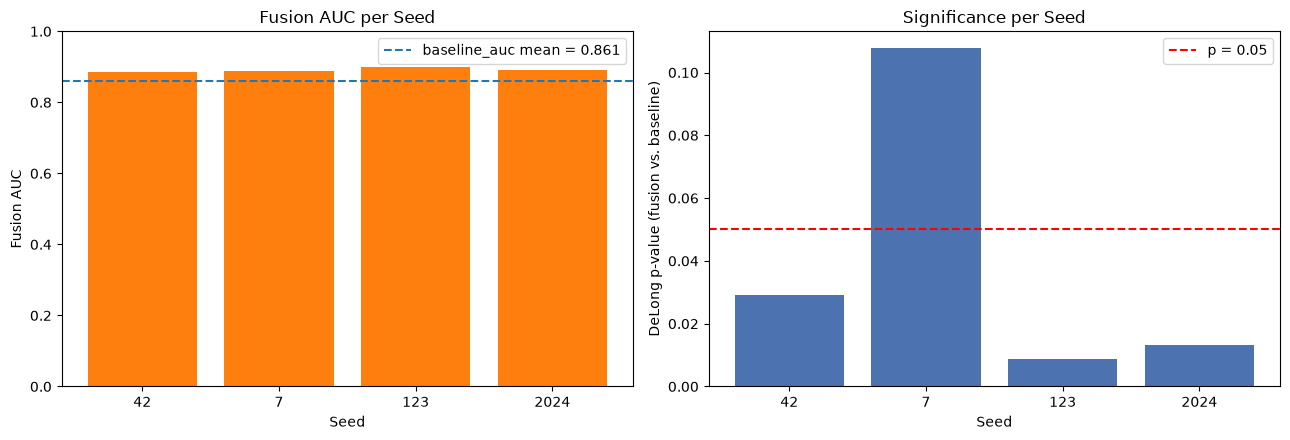

In [8]:
print("=== SECTION 6: Plots ===")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.bar(results_df["seed"].astype(str), results_df["fusion_auc"], color=DM_COLOR)
ax.axhline(
    results_df["baseline_auc"].mean(), color=CONTROL_COLOR, linestyle="--",
    label=f"baseline_auc mean = {results_df['baseline_auc'].mean():.3f}",
)
ax.set_xlabel("Seed")
ax.set_ylabel("Fusion AUC")
ax.set_title("Fusion AUC per Seed")
ax.set_ylim(0, 1)
ax.legend()

ax = axes[1]
ax.bar(results_df["seed"].astype(str), results_df["delong_p_fusion_vs_baseline"], color="#4C72B0")
ax.axhline(0.05, color="red", linestyle="--", label="p = 0.05")
ax.set_xlabel("Seed")
ax.set_ylabel("DeLong p-value (fusion vs. baseline)")
ax.set_title("Significance per Seed")
ax.legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "multiseed_robustness_plot.png", dpi=150)
plt.show()


## Section 7 — Save Results

- `results/multiseed_robustness_results.csv` — the Section 4 table (4
  rows: seed, gat_auc, baseline_auc, fusion_auc,
  delong_p_fusion_vs_baseline, delong_p_fusion_vs_gat,
  significant_at_0.05).
- `results/multiseed_robustness_summary.json` — all per-seed numbers plus
  the aggregate mean/std, the robustness verdict, and the Phase 16 sanity
  check.


In [9]:
print("=== SECTION 7: Save Results ===")

results_out_path = RESULTS_DIR / "multiseed_robustness_results.csv"
results_df.to_csv(results_out_path, index=False)
print(f"Saved: {results_out_path}  shape={results_df.shape}")

summary_out_path = RESULTS_DIR / "multiseed_robustness_summary.json"
summary = {
    "seeds": SEEDS,
    "per_seed_results": results_df.to_dict(orient="records"),
    "fusion_auc_mean": fusion_auc_mean,
    "fusion_auc_std": fusion_auc_std,
    "delong_p_fusion_vs_baseline_mean": p_mean,
    "delong_p_fusion_vs_baseline_std": p_std,
    "n_seeds_significant": n_significant,
    "robustness_verdict": robustness_verdict,
    "phase16_sanity_check": {
        "seed42_fusion_auc": float(seed42_row["fusion_auc"]),
        "phase16_fusion_auc": PHASE16_FUSION_AUC,
        "seed42_p_value": float(seed42_row["delong_p_fusion_vs_baseline"]),
        "phase16_p_value": PHASE16_P,
        "tolerance": TOLERANCE,
        "pass": sanity_pass,
    },
    "total_runtime_minutes": total_runtime_sec / 60,
}
with open(summary_out_path, "w") as f:
    json.dump(summary, f, indent=2, default=float)
print(f"Saved: {summary_out_path}")


=== SECTION 7: Save Results ===
Saved: results\multiseed_robustness_results.csv  shape=(4, 7)
Saved: results\multiseed_robustness_summary.json


## Section 8 — Final Summary


In [10]:
print("=== SECTION 8: Final Summary ===")
print()
print(results_df.to_string(index=False))
print()
print(f"ROBUSTNESS VERDICT: {robustness_verdict}  ({n_significant}/4 seeds significant at p<0.05)")
print(f"Phase 16 (seed=42) sanity check: {'PASS' if sanity_pass else 'FAIL'}")
print()

n_checkpoints = len(list(CHECKPOINT_DIR.glob("robustness_seed*_fold*_best.pt")))
print(f"Checkpoints saved: {n_checkpoints} (expected 20 = 4 seeds x 5 folds)")
if n_checkpoints != 20:
    issues_found.append(f"Expected 20 robustness checkpoints, found {n_checkpoints}")

print("Result files saved:")
for p in [results_out_path, summary_out_path, RESULTS_DIR / "multiseed_robustness_plot.png"]:
    print(f"  - {p}  (exists={p.exists()})")

print()
print(f"Total pipeline runtime: {total_runtime_sec / 60:.1f} minutes "
      f"(approximately 4x Phase 13's single-seed 5-fold CV runtime, as expected)")

print()
if issues_found:
    print(f"{len(issues_found)} issue(s) found:")
    for i in issues_found:
        print(f"  - {i}")
else:
    print("0 issues found")


=== SECTION 8: Final Summary ===

 seed  gat_auc  baseline_auc  fusion_auc  delong_p_fusion_vs_baseline  delong_p_fusion_vs_gat  significant_at_0.05
   42 0.877960      0.858834    0.886703                     0.029047                0.520038                 True
    7 0.881239      0.862842    0.887432                     0.107724                0.579348                False
  123 0.898361      0.860474    0.899454                     0.008838                0.926226                 True
 2024 0.891985      0.861566    0.891439                     0.013290                0.964668                 True

ROBUSTNESS VERDICT: ROBUST  (3/4 seeds significant at p<0.05)
Phase 16 (seed=42) sanity check: PASS

Checkpoints saved: 20 (expected 20 = 4 seeds x 5 folds)
Result files saved:
  - results\multiseed_robustness_results.csv  (exists=True)
  - results\multiseed_robustness_summary.json  (exists=True)
  - results\multiseed_robustness_plot.png  (exists=True)

Total pipeline runtime: 23.3 minut